# Which Binance tokens get a delisting notice? A time-varying Cox model

Each row of `panel` is one token in one month. A row covers `[start_age, stop_age)`, measured in days since the asset first listed,
and `event = True` if Binance announced the token's delisting that month (the asset leaves the risk set at the announcement). Features are measured 30 days before the month starts (`*_lag30`),
so the model only sees trading from well before any announcement (notices come at most 15 days before the last trading day).

Run `python load_db.py` first to build `crypto.duckdb`.

In [1]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score
from lifelines import CoxTimeVaryingFitter

con = duckdb.connect('crypto.duckdb', read_only=True)
q = lambda sql: con.sql(sql).df()

panel = q('''SELECT p.*, l.last_date, l.needs_review, l.asset_left_truncated
             FROM panel p JOIN lifetimes l USING (symbol)''')
panel['month_start'] = pd.to_datetime(panel['month_start'])

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})
BLUE, GREY = '#2a78d6', '#8a8a8a'
print(f'{len(panel):,} token-months, {panel.asset_id.nunique()} assets, {int(panel.event.sum())} delistings')

25,049 token-months, 544 assets, 136 delistings


## 1. The data

### Exits by year

A ticker that stops trading is not always a failure: 43 were renames (MATIC → POL) and 5 were mergers.
Only delistings count as events; renames are chained into one asset and mergers are censored.

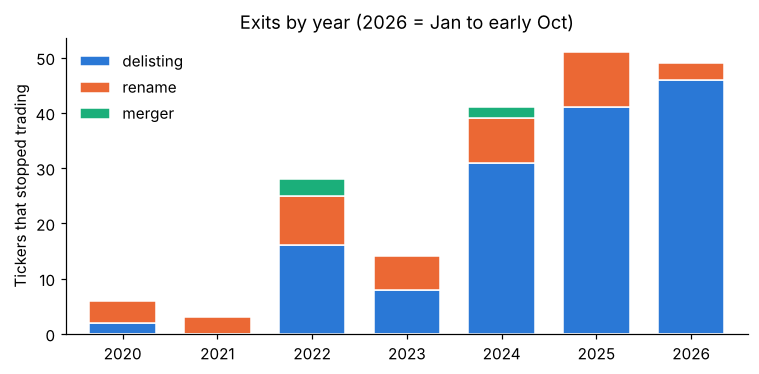

,delisting,rename,merger
year,,,
2020,2,4,0
2021,0,3,0
2022,16,9,3
2023,8,6,0
2024,31,8,2
2025,41,10,0
2026,46,3,0


In [2]:
exits = q('''SELECT year(last_date) AS year,
                    COUNT(*) FILTER (WHERE exit_type = 'delisting') AS delisting,
                    COUNT(*) FILTER (WHERE exit_type = 'rename')    AS rename,
                    COUNT(*) FILTER (WHERE exit_type = 'merger')    AS merger
             FROM lifetimes WHERE stopped GROUP BY 1 ORDER BY 1''').set_index('year')

fig, ax = plt.subplots(figsize=(7, 3.5))
exits.plot.bar(stacked=True, ax=ax, color=[BLUE, '#eb6834', '#1baf7a'], width=0.7, rot=0, edgecolor='white')
ax.set_xlabel('')
ax.set_ylabel('Tickers that stopped trading')
ax.set_title('Exits by year (2026 = Jan to early Oct)')
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig('figures/exits_by_year.png', dpi=150)
plt.show()
exits

### Trading picks up before a delisting

Average daily dollar volume in a token's last 30 days, divided by the 60 days before that.
Delisted tokens trade more at the end, mostly after the notice. The model's features stop 30 days before each month starts.

In [3]:
q('''WITH d AS (
       SELECT l.symbol, l.exit_type,
              AVG(p.close * p.volume) FILTER (WHERE p.ts > l.last_date - 30) AS last_30d,
              AVG(p.close * p.volume) FILTER (WHERE p.ts <= l.last_date - 30 AND p.ts > l.last_date - 90) AS prior_60d
       FROM lifetimes l JOIN prices p USING (symbol)
       WHERE l.stopped
       GROUP BY 1, 2)
     SELECT exit_type, COUNT(*) AS tickers,
            ROUND(MEDIAN(last_30d / prior_60d), 2) AS median_ratio,
            ROUND(100 * AVG(CASE WHEN last_30d > prior_60d THEN 1 ELSE 0 END), 1) AS pct_higher
     FROM d GROUP BY 1 ORDER BY 2 DESC''')

,exit_type,tickers,median_ratio,pct_higher
0,delisting,144,1.51,68.8
1,rename,43,1.11,55.8
2,merger,5,0.69,0.0


### Look-ahead check

Recompute two panel features in pandas for 200 random rows, using only prices strictly before each cutoff.

In [4]:
prices = q('SELECT symbol, ts, close, close * volume AS dv FROM prices')
prices['ts'] = pd.to_datetime(prices['ts'])
by_symbol = dict(tuple(prices.groupby('symbol')))

sample = panel.dropna(subset=['log_dv30_lag30']).sample(200, random_state=1)
mismatches = 0
for _, r in sample.iterrows():
    for lag in [0, 30]:
        cutoff = r.month_start - pd.Timedelta(days=lag)
        past = by_symbol[r.symbol]
        past = past[past.ts < cutoff]
        window = past[past.ts >= past.ts.max() - pd.Timedelta(days=29)]
        log_dv30 = np.log(window.dv.mean() + 1)
        drawdown = past.close.iloc[-1] / past.close.max() - 1
        mismatches += abs(log_dv30 - r[f'log_dv30_lag{lag}']) > 1e-9
        mismatches += abs(drawdown - r[f'drawdown_lag{lag}']) > 1e-9
print(f'{mismatches} mismatches out of {len(sample) * 4} recomputed values')

0 mismatches out of 800 recomputed values


/tmp/ipykernel_301/1971300120.py:9: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  cutoff = r.month_start - pd.Timedelta(days=lag)
/tmp/ipykernel_301/1971300120.py:12: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  window = past[past.ts >= past.ts.max() - pd.Timedelta(days=29)]


## 2. Cox model

Five features, each winsorized at 1%/99% and standardized, so a hazard ratio is per one standard deviation.

In [5]:
FEATS = ['log_dv30_lag30', 'dv_trend_lag30', 'vol30_lag30', 'ret90_lag30', 'drawdown_lag30']
X = ['volume', 'volume_trend', 'volatility', 'return_90d', 'drawdown']
COLS = ['asset_id', 'start_age', 'stop_age', 'event']


def prep(data, feats=FEATS, ref=None):
    # winsorize at 1%/99% and standardize; cutoffs, mean and SD come from `ref` (the training set out of sample)
    ref = data if ref is None else ref
    d = data.dropna(subset=feats).rename(columns=dict(zip(feats, X)))
    r = ref.dropna(subset=feats).rename(columns=dict(zip(feats, X)))
    lo, hi = r[X].quantile(0.01), r[X].quantile(0.99)
    r = r[X].clip(lo, hi, axis=1)
    d[X] = (d[X].clip(lo, hi, axis=1) - r.mean()) / r.std()
    d['event'] = d['event'].astype(int)
    return d


def fit(d, features):
    return CoxTimeVaryingFitter().fit(d[COLS + features], id_col='asset_id', event_col='event',
                                      start_col='start_age', stop_col='stop_age')


df = prep(panel)
cox = fit(df, X)
summary = cox.summary[['exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p']]
summary.columns = ['HR', 'lower', 'upper', 'p']
summary.round(3)

,HR,lower,upper,p
covariate,,,,
volume,0.272,0.199,0.372,0.000
volume_trend,1.080,0.846,1.380,0.536
volatility,1.917,1.532,2.398,0.000
return_90d,0.556,0.419,0.737,0.000
drawdown,1.335,0.928,1.921,0.120


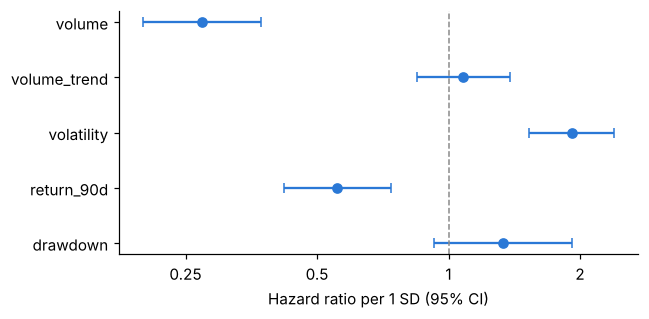

In [6]:
s = summary.iloc[::-1]
fig, ax = plt.subplots(figsize=(6, 3))
ax.errorbar(s.HR, range(len(s)), xerr=[s.HR - s.lower, s.upper - s.HR], fmt='o', color=BLUE, capsize=3)
ax.axvline(1, color=GREY, lw=1, ls='--')
ax.set_yticks(range(len(s)))
ax.set_yticklabels(s.index)
ax.set_xscale('log')
ax.minorticks_off()
ax.set_xticks([0.25, 0.5, 1, 2])
ax.set_xticklabels(['0.25', '0.5', '1', '2'])
ax.set_xlabel('Hazard ratio per 1 SD (95% CI)')
plt.tight_layout()
plt.savefig('figures/hazard_ratios.png', dpi=150)
plt.show()

Low volume is by far the strongest signal: one standard deviation more volume cuts the delisting hazard by about 70%.
Weak 90-day returns and high volatility also raise the hazard. Volume trend (last 30 days vs last 180) adds nothing (p = 0.54).

## 3. Proportional hazards check

Interact every feature with log(age). If the effects were constant over a token's life, these terms would be zero.

In [7]:
df['log_age'] = np.log(df['start_age']) - np.log(df['start_age']).mean()
XA = [x + '_x_age' for x in X]
for x in X:
    df[x + '_x_age'] = df[x] * df['log_age']

cox_age = fit(df, X + XA)
lr = 2 * (cox_age.log_likelihood_ - cox.log_likelihood_)
print(f'LR = {lr:.2f}, df = {len(XA)}, p = {stats.chi2.sf(lr, len(XA)):.4f}')
cox_age.summary.loc[XA, ['exp(coef)', 'p']].round(3)

LR = 25.60, df = 5, p = 0.0001


,exp(coef),p
covariate,,
volume_x_age,0.788,0.410
volume_trend_x_age,0.653,0.122
volatility_x_age,2.612,0.000
return_90d_x_age,1.143,0.676
drawdown_x_age,0.345,0.008


Volatility and drawdown change with age. A simpler way to show it: let their effects differ for tokens younger than two years.
The 1- and 3-year cutoffs check that the result does not depend on the choice of two years.

In [8]:
def hr(model, terms):
    # hazard ratio and 95% CI of a sum of coefficients
    b = model.params_
    V = pd.DataFrame(np.asarray(model.variance_matrix_), index=b.index, columns=b.index)
    est = b[terms].sum()
    se = np.sqrt(V.loc[terms, terms].values.sum())
    return f'{np.exp(est):.2f} ({np.exp(est - 1.96 * se):.2f}–{np.exp(est + 1.96 * se):.2f})'


def add_young(d, years=2):
    d['young'] = (d['start_age'] < 365 * years).astype(int)
    d['volatility_x_young'] = d['volatility'] * d['young']
    d['drawdown_x_young'] = d['drawdown'] * d['young']
    return d


XY = X + ['volatility_x_young', 'drawdown_x_young']
rows = {}
for years in [1, 2, 3]:
    d = add_young(df.copy(), years)
    m = fit(d, XY)
    rows[f'{years} year'] = {
        'young events': int(d.loc[d.young == 1, 'event'].sum()),
        'volatility, older': hr(m, ['volatility']),
        'volatility, young': hr(m, ['volatility', 'volatility_x_young']),
        'drawdown, older': hr(m, ['drawdown']),
        'drawdown, young': hr(m, ['drawdown', 'drawdown_x_young']),
    }
pd.DataFrame(rows)

,1 year,2 year,3 year
young events,3,17,37
"volatility, older",1.93 (1.54–2.42),2.11 (1.66–2.67),2.31 (1.80–2.96)
"volatility, young",1.44 (0.38–5.50),1.09 (0.60–1.97),1.27 (0.85–1.91)
"drawdown, older",1.19 (0.79–1.79),0.82 (0.47–1.42),0.73 (0.38–1.39)
"drawdown, young",4.01 (1.12–14.41),3.45 (1.93–6.15),2.53 (1.57–4.08)


For young tokens, trading close to the all-time high is the warning sign (`drawdown` = price / running max − 1, so a higher value means closer to the peak); for older tokens, high volatility is.
The pattern holds with a 2- or 3-year cutoff. With a 1-year cutoff only 3 young tokens were delisted, too few to say anything.

## 4. Robustness

The two-year model, re-estimated under different choices.

In [9]:
def two_year_model(data, feats=FEATS):
    d = add_young(prep(data, feats))
    m = fit(d, XY)
    return pd.Series({
        'volume': hr(m, ['volume']),
        'volume_trend': hr(m, ['volume_trend']),
        'return_90d': hr(m, ['return_90d']),
        'volatility, older': hr(m, ['volatility']),
        'volatility, young': hr(m, ['volatility', 'volatility_x_young']),
        'drawdown, older': hr(m, ['drawdown']),
        'drawdown, young': hr(m, ['drawdown', 'drawdown_x_young']),
        'events': int(d['event'].sum()),
    })


LAG0 = [f.replace('lag30', 'lag0') for f in FEATS]
with_pairs = panel.assign(event=panel.any_delisting)
review = panel.loc[panel.needs_review == 1, 'asset_id'].unique()

robust = pd.DataFrame({
    'main': two_year_model(panel),
    'incl. USDT-pair removals': two_year_model(with_pairs),
    'drop needs_review': two_year_model(panel[~panel.asset_id.isin(review)]),
    'lag0 features': two_year_model(panel, LAG0),
    'drop left-truncated': two_year_model(panel[~panel.asset_left_truncated]),
})
robust.to_csv('results_robustness.csv')
robust

,main,incl. USDT-pair removals,drop needs_review,lag0 features,drop left-truncated
volume,0.29 (0.21–0.39),0.33 (0.24–0.44),0.30 (0.22–0.41),0.27 (0.20–0.37),0.30 (0.22–0.42)
volume_trend,1.04 (0.81–1.33),0.97 (0.77–1.24),1.01 (0.79–1.30),1.24 (0.97–1.58),0.96 (0.73–1.25)
return_90d,0.53 (0.40–0.71),0.60 (0.45–0.79),0.55 (0.41–0.73),0.45 (0.34–0.60),0.56 (0.41–0.76)
"volatility, older",2.11 (1.66–2.67),2.06 (1.63–2.60),2.11 (1.67–2.68),2.14 (1.70–2.67),2.17 (1.66–2.83)
"volatility, young",1.09 (0.60–1.97),0.91 (0.52–1.61),1.08 (0.59–2.00),0.70 (0.34–1.47),1.25 (0.68–2.29)
"drawdown, older",0.82 (0.47–1.42),0.72 (0.41–1.27),0.80 (0.46–1.40),0.79 (0.44–1.41),0.80 (0.42–1.50)
"drawdown, young",3.45 (1.93–6.15),2.30 (1.34–3.96),3.08 (1.66–5.71),3.10 (1.66–5.82),3.62 (1.97–6.64)
events,136,144,134,136,110


The signs and rough sizes hold in every version. Unlagged features (`lag0`) give similar results: they stop at the
start of the month, so they are also free of post-announcement trading.

Volume trend is the one fragile result. With the last trading month as the event it had HR 1.27 (p = 0.03); with the
announcement month it is 1.04 (0.81–1.33). The earlier effect came from event timing, not from the token.

## 5. Out of sample

Walk-forward validation with an expanding window, refit once a year: 2025 is scored by a model fit on all months
before 2025, and 2026 by a model refit on all months before 2026. Every test month is scored only by a model that never
saw it, and the 2026 model learns from the 2025 delistings, as it would in practice. Winsorizing and standardizing use
each fold's training data only. Within each test month, tokens are ranked by predicted risk.

The age interactions were found on the full sample, which includes the test period. Before 2025 alone the
proportional hazards test finds nothing (next cell), so the five-feature model without interactions is the fair out-of-sample result.

In [10]:
# Proportional hazards test on the first training window only (months before 2025)
before = prep(panel[panel.month_start < pd.Timestamp('2025-01-01')])
t = before.copy()
t['log_age'] = np.log(t['start_age']) - np.log(t['start_age']).mean()
for x in X:
    t[x + '_x_age'] = t[x] * t['log_age']
lr = 2 * (fit(t, X + XA).log_likelihood_ - fit(t, X).log_likelihood_)
print(f'PH test, before 2025 only: LR = {lr:.2f}, p = {stats.chi2.sf(lr, len(XA)):.2f}')

PH test, before 2025 only: LR = 3.63, p = 0.60


In [11]:
TEST_YEARS = [2025, 2026]


def walk_forward(features):
    # Expanding window: each test year is scored by a model fit on all months before it
    folds = []
    for year in TEST_YEARS:
        start, end = pd.Timestamp(f'{year}-01-01'), pd.Timestamp(f'{year + 1}-01-01')
        past = panel[panel.month_start < start]
        train = add_young(prep(past))
        # winsorizing cutoffs, mean and SD come from the training window only
        test = add_young(prep(panel[(panel.month_start >= start) & (panel.month_start < end)], ref=past))
        test['risk'] = fit(train, features).predict_log_partial_hazard(test[features]).values
        test['test_year'] = year
        test['train_events'] = int(train.event.sum())
        folds.append(test)
    s = pd.concat(folds)
    # rank within each month: small rank = riskiest tokens that month
    s['rank'] = s.groupby('month_start')['risk'].rank(pct=True, ascending=False)
    return s


def metrics(s):
    caught = s.loc[s.event == 1, 'rank']
    return {'AUC': round(roc_auc_score(s.event, s.risk), 3),
            'top 10% catches': f'{caught.le(0.1).mean():.0%}',
            'top 20% catches': f'{caught.le(0.2).mean():.0%}',
            'test events': int(s.event.sum())}


models = {'volume only': ['volume'], 'five features': X, 'five features + age terms*': XY}
runs = {name: walk_forward(features) for name, features in models.items()}
scored = runs['five features']

oos = pd.DataFrame({name: metrics(s) for name, s in runs.items()}).T
oos

,AUC,top 10% catches,top 20% catches,test events
volume only,0.698,31%,51%,87
five features,0.742,38%,56%,87
five features + age terms*,0.785,46%,60%,87


In [12]:
# The same metrics for each test year, and how many delistings each model was fit on
by_year = pd.DataFrame({
    (name, year): {**metrics(s[s.test_year == year]),
                   'train events': int(s.loc[s.test_year == year, 'train_events'].iloc[0])}
    for name, s in runs.items() if name != 'five features + age terms*'
    for year in TEST_YEARS
}).T
by_year

AUC top 10% catches top 20% catches test events  \
volume only   2025  0.694             27%             46%          41   
              2026  0.726             35%             54%          46   
five features 2025   0.75             32%             56%          41   
              2026   0.76             43%             57%          46   

                   train events  
volume only   2025           49  
              2026           90  
five features 2025           49  
              2026           90

\* Age terms chosen using the full sample, so this row is optimistic.

The five-feature model beats volume alone in both test years: AUC 0.750 vs 0.694 in 2025 and 0.760 vs 0.726 in 2026.
Each month's riskiest 10% of tokens contains 38% of the 2025–26 delisting announcements, against 10% by chance.
The pooled AUC (0.742) is a little lower than either year because the two years are scored by different models,
so their risk scores are not on exactly the same scale. The within-month ranks are not affected by this.

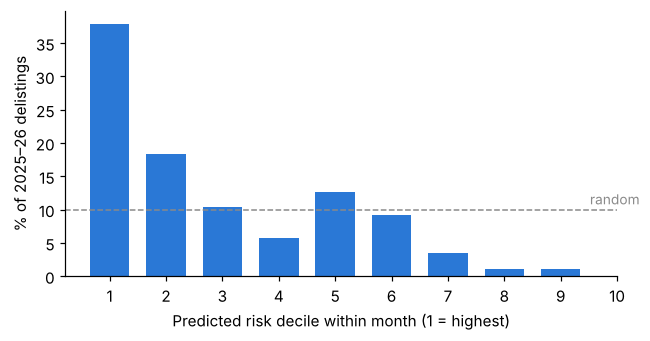

In [13]:
scored['decile'] = np.ceil(scored['rank'] * 10).astype(int)
share = scored.loc[scored.event == 1, 'decile'].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(share.index, share.values, color=BLUE, width=0.7)
ax.axhline(10, color=GREY, lw=1, ls='--')
ax.text(10.4, 10.8, 'random', color=GREY, ha='right', fontsize=9)
ax.set_xticks(range(1, 11))
ax.set_xlabel('Predicted risk decile within month (1 = highest)')
ax.set_ylabel('% of 2025–26 delistings')
plt.tight_layout()
plt.savefig('figures/oos_risk_deciles.png', dpi=150)
plt.show()

## Limitations

- Binance announces delistings in batches, so events on the same day are not independent; the confidence intervals are probably too narrow.
  lifelines' `CoxTimeVaryingFitter` has no clustered standard errors.
- 136 delistings over six years is a small number of events, especially for young tokens.
- Tokens Binance had already removed before the data was pulled are missing, so early years undercount delistings.